# Portfolio Lab: stocks, bonds and gold, 1973–2026
**Stephanie Kim** · [Project page](https://stephaniekim62-cpu.github.io/projects/portfolio-lab.html)

**Question:** how much return do you give up, and how much risk do you remove, by mixing US stocks with 10-year Treasuries and gold?

I rebuild monthly total returns for each asset from public data, deflate them by CPI, and compare mixes on return, volatility, worst decline and behavior in crises. Everything runs top to bottom in Colab with no API keys.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
BASE = "https://raw.githubusercontent.com/datasets/"
sp   = pd.read_csv(BASE + "s-and-p-500/main/data/data.csv", parse_dates=["Date"]).set_index("Date")
bond = pd.read_csv(BASE + "bond-yields-us-10y/main/data/monthly.csv", parse_dates=["Date"]).set_index("Date")
gold = pd.read_csv(BASE + "gold-prices/main/data/monthly.csv"); gold["Date"] = pd.to_datetime(gold["Date"]); gold = gold.set_index("Date")
cpi  = pd.read_csv(BASE + "cpi-us/main/data/cpiai.csv", parse_dates=["Date"]).set_index("Date")
sp.tail(3)

,SP500,Dividend,Earnings,Consumer Price Index,Long Interest Rate,Real Price,Real Dividend,Real Earnings,PE10
Date,,,,,,,,,
2026-07-01,"7,481.340",0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2026-08-01,"7,711.320",0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2026-09-01,"7,669.410",0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


## 1. Build monthly total returns
- **Stocks:** price change plus one month of dividends. The dataset stops reporting dividends in mid-2023, so after that I hold the last reported dividend yield.
- **Bonds:** buy a 10-year Treasury at par (coupon = yield), then reprice it a month later at the new yield with 9 years 11 months left. Return = price change + one month of coupon.
- **Gold:** price change. The sample starts in 1973, after the dollar's link to gold ended.

In [2]:
s = sp[["SP500", "Dividend"]].copy()
last = s[s.Dividend > 0].index.max()
s.loc[s.index > last, "Dividend"] = s.loc[last, "Dividend"] / s.loc[last, "SP500"] * s.loc[s.index > last, "SP500"]
stock = s.SP500.pct_change() + s.Dividend.shift(1) / 12 / s.SP500.shift(1)

def bond_price(coupon, yld, years):
    k = np.arange(1, int(round(years * 2)) + 1)          # semiannual periods
    return (coupon / 2 / (1 + yld / 2) ** k).sum() + 1 / (1 + yld / 2) ** k[-1]

y = bond.Rate / 100
bonds = pd.Series([np.nan] + [bond_price(y.iloc[i-1], y.iloc[i], 10 - 1/12) - 1 + y.iloc[i-1] / 12
                              for i in range(1, len(y))], index=y.index)

R = pd.concat({"Stocks": stock, "Bonds": bonds, "Gold": gold.Price.pct_change(),
               "Inflation": cpi.Index.pct_change()}, axis=1, sort=True).loc["1973-01":].dropna()
print(R.index.min().date(), "to", R.index.max().date(), "|", len(R), "months")

1973-01-01 to 2026-09-01 | 644 months


## 2. Asset and portfolio statistics

In [3]:
def portfolio(w):                      # monthly rebalanced to weights w = [stocks, bonds, gold]
    return (R[["Stocks", "Bonds", "Gold"]] * np.array(w)).sum(axis=1)

def stats(r):
    years = len(r) / 12
    wealth = (1 + r).cumprod()
    real = (1 + r) / (1 + R.Inflation) - 1
    return pd.Series({"Nominal return/yr": wealth.iloc[-1] ** (1 / years) - 1,
                      "Real return/yr": (1 + real).prod() ** (1 / years) - 1,
                      "Volatility": r.std() * np.sqrt(12),
                      "Worst decline": (wealth / wealth.cummax() - 1).min(),
                      "Worst 12 months": r.rolling(12).apply(lambda x: (1 + x).prod() - 1).min()})

mixes = {"Stocks": [1, 0, 0], "Bonds": [0, 1, 0], "Gold": [0, 0, 1], "60/40": [.6, .4, 0], "60/30/10": [.6, .3, .1]}
table = pd.DataFrame({k: stats(portfolio(w)) for k, w in mixes.items()}).T
table

,Nominal return/yr,Real return/yr,Volatility,Worst decline,Worst 12 months
Stocks,0.110,0.068,0.126,-0.490,-0.409
Bonds,0.062,0.022,0.070,-0.253,-0.170
Gold,0.080,0.039,0.171,-0.621,-0.364
60/40,0.093,0.052,0.082,-0.270,-0.235
60/30/10,0.096,0.055,0.081,-0.267,-0.244


In [4]:
R.corr().round(2)

,Stocks,Bonds,Gold,Inflation
Stocks,1.000,0.050,-0.000,-0.040
Bonds,0.050,1.000,0.040,-0.200
Gold,-0.000,0.040,1.000,0.160
Inflation,-0.040,-0.200,0.160,1.000


## 3. Growth of $10,000 after inflation

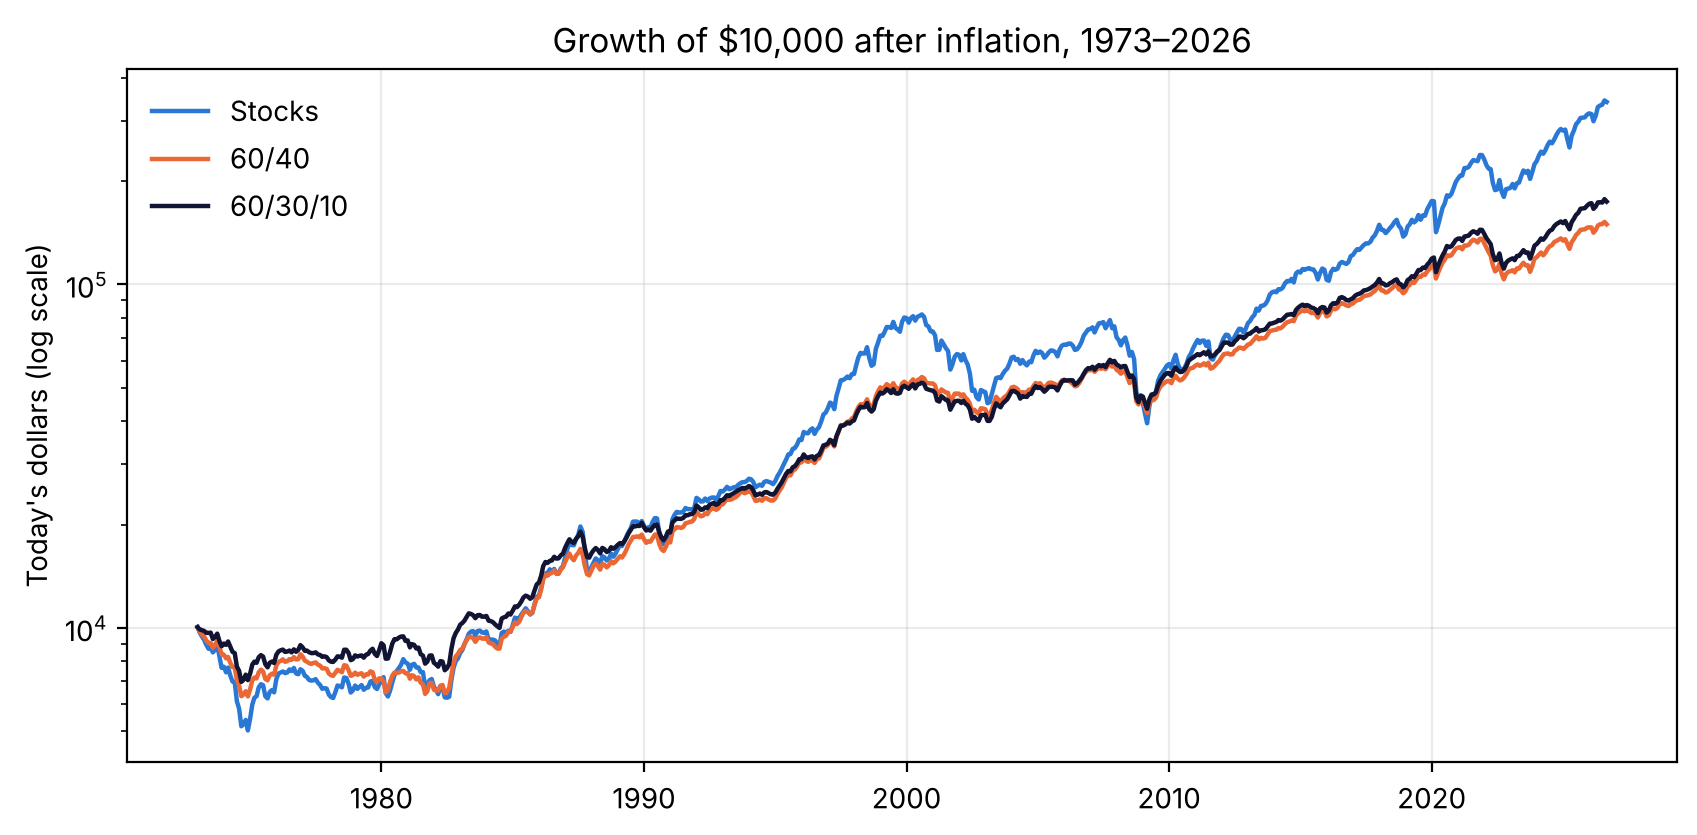

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for k, c in [("Stocks", "#2a78d6"), ("60/40", "#eb6834"), ("60/30/10", "#121433")]:
    real = (1 + portfolio(mixes[k])) / (1 + R.Inflation)
    ax.plot(10_000 * real.cumprod(), label=k, color=c, lw=1.6)
ax.set_yscale("log"); ax.set_ylabel("Today's dollars (log scale)"); ax.legend(frameon=False)
ax.set_title("Growth of $10,000 after inflation, 1973–2026"); ax.grid(alpha=.25); plt.show()

## 4. The efficient frontier: every mix in 5% steps

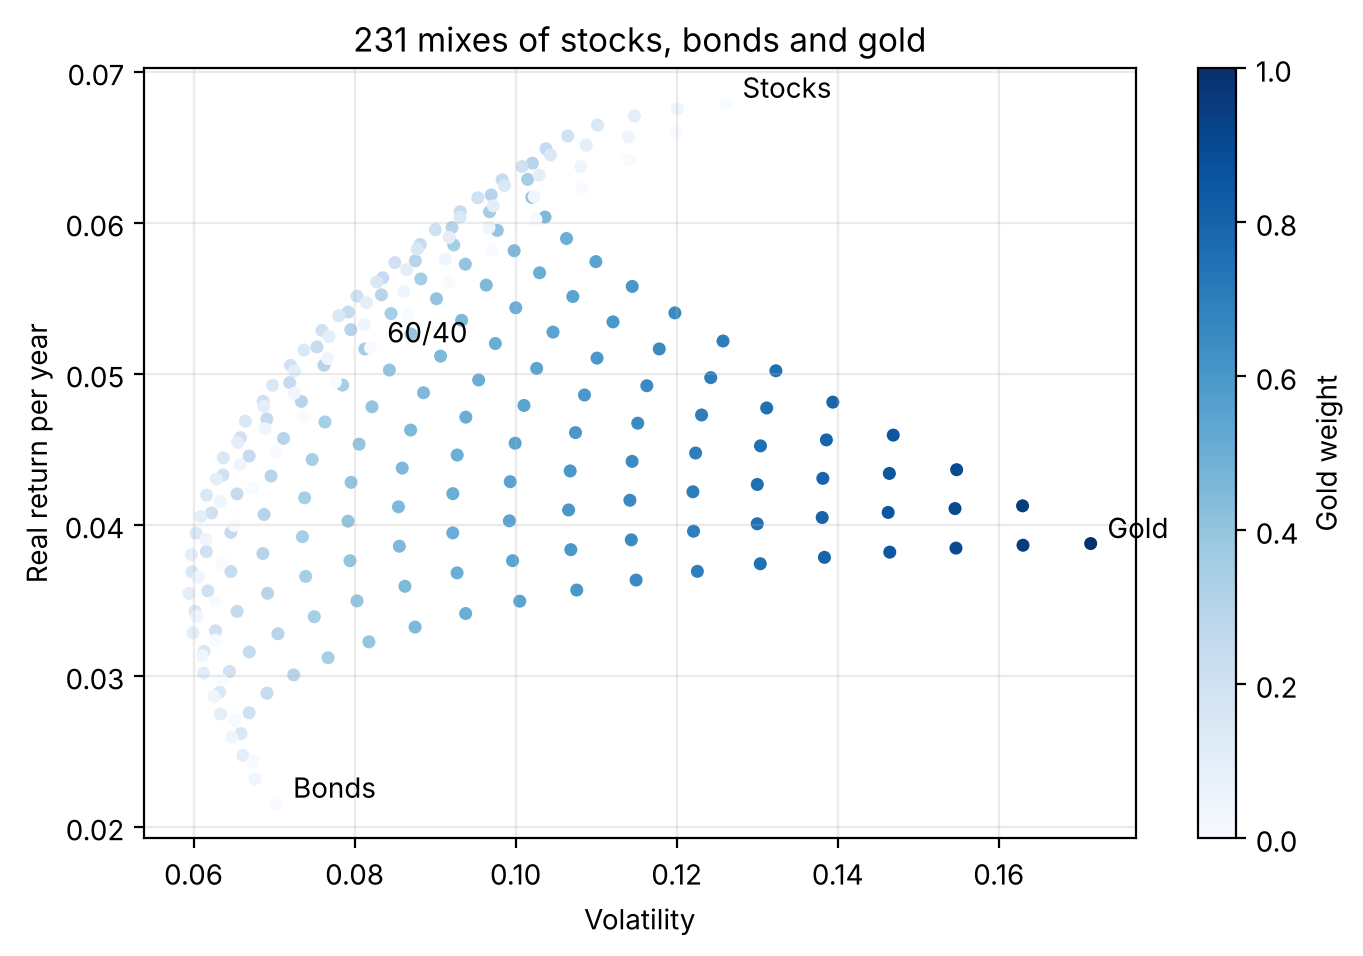

Best return per unit of risk:
Stocks             0.450
Bonds              0.400
Gold               0.150
Real               0.049
Vol                0.070
Worst             -0.183
Return per risk    0.705
Name: 161, dtype: float64


In [6]:
rows = []
for a in range(0, 101, 5):
    for b in range(0, 101 - a, 5):
        w = [a / 100, b / 100, (100 - a - b) / 100]
        st = stats(portfolio(w))
        rows.append(w + [st["Real return/yr"], st["Volatility"], st["Worst decline"]])
G = pd.DataFrame(rows, columns=["Stocks", "Bonds", "Gold", "Real", "Vol", "Worst"])
G["Return per risk"] = G.Real / G.Vol

fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(G.Vol, G.Real, c=G.Gold, cmap="Blues", s=22, edgecolor="none")
for name, w in [("Stocks", [1, 0, 0]), ("Bonds", [0, 1, 0]), ("Gold", [0, 0, 1]), ("60/40", [.6, .4, 0])]:
    r = G[(G.Stocks == w[0]) & (G.Bonds == w[1])].iloc[0]; ax.annotate(name, (r.Vol, r.Real), xytext=(6, 2), textcoords="offset points")
plt.colorbar(sc, label="Gold weight"); ax.set_xlabel("Volatility"); ax.set_ylabel("Real return per year")
ax.set_title("231 mixes of stocks, bonds and gold"); ax.grid(alpha=.25); plt.show()
print("Best return per unit of risk:"); print(G.loc[G["Return per risk"].idxmax()])

## 5. Behavior in crises

In [7]:
crises = {"1973–74 oil shock": ("1973-01", "1974-09"), "2000–02 dot-com": ("2000-08", "2002-09"),
          "2008 crisis": ("2007-10", "2009-02"), "2020 Covid": ("2020-01", "2020-03"), "2022 inflation": ("2021-12", "2022-09")}
pd.DataFrame({name: {k: (1 + portfolio(w).loc[a:b]).prod() - 1 for k, w in mixes.items()}
              for name, (a, b) in crises.items()}).T

,Stocks,Bonds,Gold,60/40,60/30/10
1973–74 oil shock,-0.384,0.005,1.375,-0.247,-0.171
2000–02 dot-com,-0.393,0.322,0.131,-0.160,-0.174
2008 crisis,-0.443,0.205,0.323,-0.232,-0.222
2020 Covid,-0.161,0.100,0.076,-0.057,-0.059
2022 inflation,-0.165,-0.143,-0.077,-0.155,-0.148


## 6. Worst 10-year stretch after inflation

In [8]:
for k in ["Stocks", "60/40", "60/30/10"]:
    real = (1 + portfolio(mixes[k])) / (1 + R.Inflation) - 1
    roll = (1 + real).rolling(120).apply(np.prod, raw=True) ** (1 / 10) - 1
    print(f"{k:9s} worst 10-yr real return {roll.min():6.1%} (ending {roll.idxmin():%b %Y}); "
          f"share of 10-yr windows below zero {(roll.dropna() < 0).mean():.1%}")

Stocks    worst 10-yr real return  -5.9% (ending Mar 2009); share of 10-yr windows below zero 6.9%
60/40     worst 10-yr real return  -1.7% (ending Dec 1982); share of 10-yr windows below zero 3.4%
60/30/10  worst 10-yr real return  -1.1% (ending Mar 2009); share of 10-yr windows below zero 1.7%


## Takeaways
1. **60/40 kept about three-quarters of stocks' real return** (5.2% vs 6.8% a year) with about two-thirds of the volatility and about half the worst decline (−27% vs −49%).
2. **The best return per unit of risk was around 45/40/15.** All three assets were nearly uncorrelated over the full period, so each one added diversification.
3. **The protection rotates.** Bonds protected in 2000–02, 2008 and 2020. Gold protected in the 1970s inflation. In 2022 stocks and bonds fell together.

## Limitations
- Shiller's S&P prices are **monthly averages**, which smooths volatility and drawdowns. Covid shows as −16% here, while the actual peak-to-trough fall was over 30%.
- Dividends after June 2023 are estimated. There are no fees, taxes or trading costs, and rebalancing is monthly.
- 1981–2020 was a long period of falling interest rates, which flattered bonds.

**Next steps:** add T-bills as a cash asset, test annual rebalancing, and add international stocks and REITs using ETF data from `yfinance`.